# Assignment 8 — SOFR OIS Calibration and Hedging Risk

Use the library APIs to calibrate SOFR to OIS quotes, report a swap's risk by OIS tenor, and construct a first-order hedge.

Calibration uses **bootstrap** with a **piecewise constant interpolator** for instantaneous forward rates and flat extrapolation. Use only OIS instruments and keep the funding spread fixed at zero.

Complete these five TODO blocks in `fixedincomelib` (keep the existing function signatures):

- **2a, 2b** — `yield_curve/valuation_engine.py`, `ValuationEngineProductRfrSwap.calculate_value`: calculate the annuity per unit notional and the OIS par rate.
- **2c** — the same class, `grad_at_par`: calculate the par-rate gradient with respect to $X^I$ using both leg gradients.
- **3** — `yield_curve/yield_curve_model.py`, `YieldCurve.calculate_model_jacobian`: construct each calibration-instrument row of $J$.
- **4** — `valuation/utilities.py`, `risk_calculation`: convert $\nabla_{X^I}V$ to $\nabla_{X^M}V$.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

from fixedincomelib import (
    qfCreateData1D, qfCreateDataCollection, qfCreateDataGeneric,
    qfCreateBuildMethod, qfCreateModelBuildMethodCollection, qfCreateModel,
    qfCreateValuationParameters, qfCreateValuationParametersCollection,
    qfCreateProductFromDataConvention, qfCreateValueReport,
)

ROOT = Path.cwd()
pd.set_option("display.max_rows", 30)
pd.set_option("display.precision", 6)

## 1. Read market quotes

Read `SOFR OIS.xlsx` into `market_data`, converting bp to decimal rates immediately by dividing by 10,000. All subsequent API inputs use these decimal rates. Use the workbook date as the valuation date.

In [2]:
market_data = pd.read_excel(
    ROOT / "fixedincomelib/data/SOFR OIS.xlsx", index_col="Date", engine="openpyxl",
).T / 10_000
value_date = pd.Timestamp(market_data.columns[0]).date().isoformat()
market_data.columns = ["values"]
market_data.index.name = "Tenor"

print("Market / valuation date:", value_date)
display(market_data)

Market / valuation date: 2026-10-09


,values
Tenor,
1Y,0.044779
2Y,0.046567
3Y,0.047073
4Y,0.047203
5Y,0.047320
6Y,0.047499
7Y,0.047700
8Y,0.047920
9Y,0.048160


## 2. Calibrate SOFR

Follow the template: create a funding-parameter table and a common build method, then call `qfCreateModel`. The library bootstraps one node at a time so each calibration instrument has zero PV, anchoring nodes at the instruments' last payment dates.

Use one zero-spread quote of 0 at 1Y for the funding component, with piecewise constant interpolation and flat extrapolation.

In [3]:
funding_parameters = qfCreateDataGeneric(
    "DATA GENERIC", "USD-FUNDING",
    pd.DataFrame([
        ["OVERNIGHT INDEX SWAP", "USD-SOFR-OIS", "SOFR-1B-FLAT"],
        ["SPREAD ZERO RATE", "SOFR-1B-FLAT-OVER-SOFR-1B-ZERO-SPREAD", "SOFR-1B-FLAT"],
    ], columns=["DATA TYPE", "DATA CONVENTION", "FUNDING IDENTIFIER"]),
)

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod("YIELD_CURVE_COMMON", {
        "TARGET": "USD",
        "FUNDING PARAMETERS": "USD-FUNDING",
        "SOLVER": "BRENTQ",
    }),
    qfCreateBuildMethod("YIELD_CURVE_INDEX", {
        "TARGET": "SOFR-1B",
        "OVERNIGHT INDEX SWAP": "USD-SOFR-OIS",
        "INTERPOLATION METHOD": "PIECEWISE_CONSTANT_LEFT_CONTINUOUS",
        "EXTRAPOLATION METHOD": "FLAT",
    }),
    qfCreateBuildMethod("YIELD_CURVE_FUNDING", {
        "TARGET": "SOFR-1B-FLAT",
        "SPREAD ZERO RATE": "SOFR-1B-FLAT-OVER-SOFR-1B-ZERO-SPREAD",
        "INTERPOLATION METHOD": "PIECEWISE_CONSTANT_LEFT_CONTINUOUS",
        "EXTRAPOLATION METHOD": "FLAT",
    }),
])

valuation_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": "SOFR-1B-FLAT",
    }),
])

data = qfCreateDataCollection([
    qfCreateData1D("OVERNIGHT INDEX SWAP", "USD-SOFR-OIS", market_data),
    qfCreateData1D(
        "SPREAD ZERO RATE", "SOFR-1B-FLAT-OVER-SOFR-1B-ZERO-SPREAD",
        pd.DataFrame({"values": [0.0]}, index=["1Y"]),
    ),
    funding_parameters,
])
model = qfCreateModel(value_date, "YIELD_CURVE", data, build_methods)
sofr = model.retrieve_model_component("SOFR-1B")
calibration_swaps = sofr.calibration_product

display(pd.DataFrame({
    "OIS tenor": [row[2] for row in sofr.market_data],
    "Node / last payment": [swap.last_date.ISO() for swap in calibration_swaps],
    "Time (years)": sofr.state_data[0],
    "Internal forward (decimal)": sofr.state_data[1],
}))

,OIS tenor,Node / last payment,Time (years),Internal forward (decimal)
0,1Y,2027-10-14,1.013699,0.044414
1,2Y,2028-10-12,2.008826,0.048094
2,3Y,2029-10-11,3.005479,0.047686
3,4Y,2030-10-11,4.005479,0.047162
4,5Y,2031-10-14,5.013699,0.047373
5,6Y,2032-10-14,6.014290,0.048151
6,7Y,2033-10-13,7.010959,0.048657
7,8Y,2034-10-12,8.008219,0.049273
8,9Y,2035-10-11,9.005479,0.049975
9,10Y,2036-10-14,10.014290,0.051061


In [4]:
par_rates = np.array([
    qfCreateValueReport(model, swap, valuation_parameters, "ParRateOrSpread")
    for swap in calibration_swaps
])
repricing = pd.DataFrame({
    "Market (bp)": market_data["values"] * 1e4,
    "Model (bp)": par_rates * 1e4,
    "Error (bp)": (par_rates - market_data["values"]) * 1e4,
})
display(repricing)

,Market (bp),Model (bp),Error (bp)
Tenor,,,
1Y,447.795,447.795,5.258294e-10
2Y,465.672,465.672,1.015160e-10
3Y,470.730,470.730,7.223389e-11
4Y,472.032,472.032,6.224188e-11
5Y,473.200,473.200,1.133815e-10
6Y,474.988,474.988,4.003742e-11
7Y,477.000,477.000,2.789435e-11
8Y,479.203,479.203,2.393918e-11
9Y,481.600,481.600,2.074729e-11


## 3. Value a swap and report risk to OIS quotes

Use `qfCreateValueReport` with `PV` and `FirstOrderRisk` for a USD 1,000,000 **receive-fixed** 9Y6M OIS at 4.5%.

For row gradients, the library calculates quote risk analytically using

$$
J=\frac{\partial X^M}{\partial X^I},\qquad
\nabla_{X^M}V=\nabla_{X^I}V\,J^{-1}.
$$

In [5]:
target = qfCreateProductFromDataConvention(
    value_date, "USD-SOFR-OIS", "9Y6M", 0.045,
    notional=1_000_000, pay_or_rec="receive",
)
target_pv = qfCreateValueReport(model, target, valuation_parameters, "PV")[0][1]
print(f"Receive-fixed swap PV: USD {target_pv:,.2f}")

risk = qfCreateValueReport(model, target, valuation_parameters, "FirstOrderRisk").display()
risk = risk.loc[risk["DATA_TYPE"] == "OVERNIGHT INDEX SWAP"].reset_index(drop=True)
risk["MARKET_QUOTE"] = risk["MARKET_QUOTE"].astype(float)
display(risk[["AXIS1", "MARKET_QUOTE", "VALUES"]].rename(columns={
    "AXIS1": "OIS tenor",
    "MARKET_QUOTE": "Market quote (decimal)",
    "VALUES": "Target risk (USD / +1 bp)",
}))

Receive-fixed swap PV: USD -24,829.03


,OIS tenor,Market quote (decimal),Target risk (USD / +1 bp)
0,1Y,0.044779,1.336135
1,2Y,0.046567,0.382009
2,3Y,0.047073,0.597304
3,4Y,0.047203,1.038225
4,5Y,0.047320,0.823435
5,6Y,0.047499,1.766412
6,7Y,0.047700,1.566545
7,8Y,0.047920,3.531423
8,9Y,0.048160,-355.339457
9,10Y,0.048430,-401.432157


## 4. Express the hedge in OIS instruments

Create one USD 1,000,000 receive-fixed par OIS per calibration tenor, using its market quote as the fixed coupon. Obtain each hedge's quote risk with `qfCreateValueReport`.

Let $B_{ij}$ be the risk of hedge instrument $i$ to OIS quote $j$, in USD/bp. $B$ is $17\times17$. Select the 17 OIS entries of the target's quote gradient and solve for the hedge weights $w$:

$$
B^\top w=-\left[\left(10^{-4}\nabla_{X^M}V\right)_{\mathrm{OIS}}\right]^\top.
$$

A positive $w_i$ means receive fixed; a negative $w_i$ means pay fixed. The signed hedge notional in USD is $w_i\times 1{,}000{,}000$.

In [6]:
hedges = [
    qfCreateProductFromDataConvention(
        value_date, "USD-SOFR-OIS", tenor, rate,
        notional=1_000_000, pay_or_rec="receive",
    )
    for tenor, rate in market_data["values"].items()
]
B = np.array([
    qfCreateValueReport(model, hedge, valuation_parameters, "FirstOrderRisk")
    .display().query("DATA_TYPE == 'OVERNIGHT INDEX SWAP'")["VALUES"].to_numpy()
    for hedge in hedges
])
weights = np.linalg.solve(B.T, -risk["VALUES"].to_numpy())

display(pd.DataFrame({
    "OIS tenor": market_data.index,
    "Target risk (USD / bp)": risk["VALUES"].to_numpy(),
    "1m receive-fixed hedge risk to own quote": np.diag(B),
    "Signed receive-fixed hedge notional (USD)": weights * 1_000_000,
    "Residual risk (USD / bp)": risk["VALUES"].to_numpy() + weights @ B,
}))

,OIS tenor,Target risk (USD / bp),1m receive-fixed hedge risk to own quote,Signed receive-fixed hedge notional (USD),Residual risk (USD / bp)
0,1Y,1.336135,-97.770067,13666.089735,0.000000e+00
1,2Y,0.382009,-189.912728,2011.495956,0.000000e+00
2,3Y,0.597304,-277.730519,2150.660087,0.000000e+00
3,4Y,1.038225,-361.778939,2869.776317,0.000000e+00
4,5Y,0.823435,-441.907361,1863.365811,0.000000e+00
5,6Y,1.766412,-519.132398,3402.622933,0.000000e+00
6,7Y,1.566545,-591.670793,2647.663054,0.000000e+00
7,8Y,3.531423,-660.730533,5344.724260,0.000000e+00
8,9Y,-355.339457,-726.424834,-489162.044569,0.000000e+00
9,10Y,-401.432157,-789.177720,-508671.426672,-5.684342e-14


## Appendix — checks and interpretation (not part of the assignment template)

The cells above are the supplied template, unchanged. The cells below were added to show what the
numbers mean and to check them independently; they can be deleted without affecting anything above.
Full write-up: `docs/hw8-implementation.md`.


,Quote (%),Forward on bucket ending at node (%),Zero rate to node (%),Discount factor
Tenor,,,,
1Y,4.47795,4.441435,4.441435,0.955976
2Y,4.65672,4.809358,4.623696,0.911301
3Y,4.70730,4.768585,4.671743,0.869003
4Y,4.72032,4.716217,4.682846,0.828971
5Y,4.73200,4.737307,4.693798,0.790308
6Y,4.74988,4.815089,4.713977,0.753134
7Y,4.77000,4.865722,4.735549,0.717482
8Y,4.79203,4.927305,4.759428,0.683079
9Y,4.81600,4.997536,4.785796,0.649869


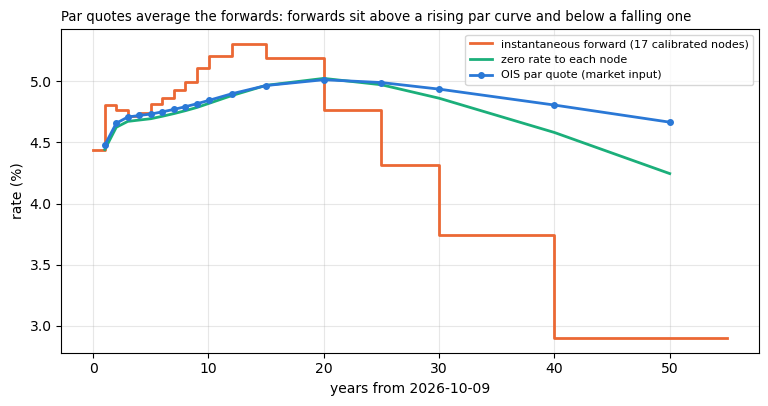

In [7]:
# A1. The calibrated curve: market par quotes, zero rates and the model's piecewise-constant forwards.
import matplotlib.pyplot as plt

node_t, node_f = sofr.state_data[0], sofr.state_data[1]
zero = np.array([-np.log(model.discount_factor("SOFR-1B", swap.last_date)) / t
                 for swap, t in zip(calibration_swaps, node_t)])
curve = pd.DataFrame({
    "Quote (%)": market_data["values"].to_numpy() * 100,
    "Forward on bucket ending at node (%)": node_f * 100,
    "Zero rate to node (%)": zero * 100,
    "Discount factor": [model.discount_factor("SOFR-1B", swap.last_date) for swap in calibration_swaps],
}, index=market_data.index)
display(curve)

fig, ax = plt.subplots(figsize=(9, 4.2))
steps_x = np.concatenate(([0.0], np.repeat(node_t, 2), [55.0]))
steps_y = np.concatenate((np.repeat(node_f, 2), [node_f[-1], node_f[-1]])) * 100
ax.plot(steps_x, steps_y, color="#eb6834", lw=2, label="instantaneous forward (17 calibrated nodes)")
ax.plot(node_t, zero * 100, color="#1baf7a", lw=2, label="zero rate to each node")
ax.plot(node_t, market_data["values"] * 100, color="#2a78d6", lw=2, marker="o", ms=4, label="OIS par quote (market input)")
ax.set_xlabel("years from " + value_date); ax.set_ylabel("rate (%)"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
ax.set_title("Par quotes average the forwards: forwards sit above a rising par curve and below a falling one", fontsize=9.5, loc="left")
plt.show()


In [8]:
# A2. The same risk in two coordinate systems, and the Jacobian that links them.
from fixedincomelib.valuation import ValuationEngineProductRegistry, ValuationRequest

engine = ValuationEngineProductRegistry.new_valuation_engine(model, target, valuation_parameters, ValuationRequest.PV)
engine.calculate_value()
state_gradient = []
engine.calculate_first_order_risk(state_gradient, 1.0, False)
state_risk = np.concatenate(state_gradient)                    # value per unit move of each internal node
J = model.model_jacobian                                       # d(quotes) / d(nodes), built lazily by the risk request
quote_risk = np.linalg.solve(J.T, state_risk)                  # the library's task-4 step, repeated here

print(f"annuity A = {engine.annuity_:.6f}   par rate K* = {engine.par_rate_or_spread():.6%}")
print(f"N * A * (K - K*) = {1_000_000 * engine.annuity_ * (0.045 - engine.par_rate_or_spread()):,.2f}   (PV above: {target_pv:,.2f})")
print(f"J: shape {J.shape}, largest entry above the diagonal {np.abs(np.triu(J, 1)).max():.1e}, condition number {np.linalg.cond(J):.1f}")
display(pd.DataFrame({
    "State risk: USD per +1bp of the forward node": state_risk[1:] * 1e-4,
    "Quote risk: USD per +1bp of the OIS quote": quote_risk[1:] * 1e-4,
    "Report value": risk["VALUES"].to_numpy(),
}, index=market_data.index).loc[:"12Y"])
print(f"Funding-spread entry (filtered out of the table in section 3): {quote_risk[0] * 1e-4:.4f} USD per +1bp")


annuity A = 7.586336   par rate K* = 4.827286%
N * A * (K - K*) = -24,829.03   (PV above: -24,829.03)
J: shape (18, 18), largest entry above the diagonal 2.2e-16, condition number 31.0


,State risk: USD per +1bp of the forward node,Quote risk: USD per +1bp of the OIS quote,Report value
Tenor,,,
1Y,-97.669721,1.336135,1.336135
2Y,-92.636658,0.382009,0.382009
3Y,-88.625557,0.597304,0.597304
4Y,-84.953628,1.038225,1.038225
5Y,-81.811445,0.823435,0.823435
6Y,-77.587560,1.766412,1.766412
7Y,-73.872571,1.566545,1.566545
8Y,-70.648269,3.531423,3.531423
9Y,-67.534606,-355.339457,-355.339457


Funding-spread entry (filtered out of the table in section 3): 12.2318 USD per +1bp


In [9]:
# A3. Does the hedge work?  Shock the QUOTES, re-calibrate the curve, and revalue target and hedges.
def calibrate(quotes):
    shocked = qfCreateDataCollection([
        qfCreateData1D("OVERNIGHT INDEX SWAP", "USD-SOFR-OIS", quotes),
        qfCreateData1D("SPREAD ZERO RATE", "SOFR-1B-FLAT-OVER-SOFR-1B-ZERO-SPREAD",
                       pd.DataFrame({"values": [0.0]}, index=["1Y"])),
        funding_parameters,
    ])
    return qfCreateModel(value_date, "YIELD_CURVE", shocked, build_methods)


def book_pnl(shocked_model):
    pv = lambda m, p: qfCreateValueReport(m, p, valuation_parameters, "PV")[0][1]
    unhedged = pv(shocked_model, target) - pv(model, target)
    hedge = sum(w * (pv(shocked_model, h) - pv(model, h)) for h, w in zip(hedges, weights) if w != 0.0)
    return unhedged, unhedged + hedge


years = np.array([float(t[:-1]) for t in market_data.index])
scenarios = {
    "all quotes +10bp": np.full(len(years), 10e-4),
    "all quotes +5bp": np.full(len(years), 5e-4),
    "steepener: -5bp at 1Y to +15bp at 50Y": (-5 + 20 * (years - 1) / 49) * 1e-4,
}
rows = []
for name, shift in scenarios.items():
    unhedged, hedged = book_pnl(calibrate(market_data + shift.reshape(-1, 1)))
    rows.append([name, float(risk["VALUES"].to_numpy() @ (shift / 1e-4)), unhedged, hedged])
display(pd.DataFrame(rows, columns=["Scenario", "Predicted by the risk report (USD)",
                                    "Actual P&L, unhedged (USD)", "Actual P&L, hedged (USD)"]))


,Scenario,Predicted by the risk report (USD),"Actual P&L, unhedged (USD)","Actual P&L, hedged (USD)"
0,all quotes +10bp,-7457.301278,-7421.821218,-0.102633
1,all quotes +5bp,-3728.650639,-3719.764695,-0.025773
2,steepener: -5bp at 1Y to +15bp at 50Y,1114.500128,1115.892156,-0.010783


**Reading the appendix.**

- *A1.* The model state is the orange staircase: one constant forward rate per bucket, each bucket ending at an
  OIS swap's last payment date. A par quote is roughly an average of the forwards up to its maturity, so the
  forwards run above the par curve while it rises (to 20Y) and far below it once it falls (2.90% for 40Y–50Y
  against a 4.67% quote).
- *A2.* In **state** coordinates the swap's risk is spread over every forward bucket it spans (about −98 to −68
  per bp, half that for the last, half-used bucket). In **quote** coordinates almost all of it sits on the 9Y and
  10Y quotes that bracket the 9Y6M maturity, because moving one earlier quote alone moves neighbouring forwards
  in opposite directions and the swap barely notices. The two are linked by
  $\nabla_{X^M}V=\nabla_{X^I}V\,J^{-1}$; $J$ is lower triangular because each bootstrap instrument only sees
  nodes up to its own. The small positive entries at 1Y–8Y come from the coupon being 33bp below par: the swap
  is short an annuity, which becomes cheaper when rates rise.
- *A3.* The risk report predicts the re-calibrated P&L to within convexity, and the hedged book moves by cents:
  the hedge removes the first-order exposure, so what remains scales with the square of the shock (compare the
  5bp and 10bp rows).
